# Logistic regression baseline

**Goal:** build the simplest sensible model for flagging laundering transactions, and show *why* each preprocessing choice matters.

- Fit on **train** only; judge on **val** only. Test splits are never loaded.
- Main metric: **PR-AUC** (average precision). With roughly 1 laundering row per 1,000, accuracy is useless: predicting "never laundering" is 99.9% accurate.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "sofia" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models.data import load_models_config, load_modelling_frame, split_xy
from src.models.metrics import evaluate_scores, best_f1_threshold
from src.models import train as T

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
cfg = load_models_config(PROJECT_ROOT / "config" / "models.json")

# Only train and val are loaded. The loader refuses test_main / test_tail.
df = load_modelling_frame(PROJECT_ROOT / "data" / "processed", splits=("train", "val"))
X_train, y_train = split_xy(df, "train", cfg)
X_val, y_val = split_xy(df, "val", cfg)
print(f"train {len(X_train):,} rows | val {len(X_val):,} rows")

train 3,046,861 rows | val 1,015,602 rows


## 1. Class balance
The positive class is tiny, which drives every later decision.

In [2]:
pd.DataFrame({
    "rows": [len(y_train), len(y_val)],
    "laundering": [int(y_train.sum()), int(y_val.sum())],
    "rate_%": [y_train.mean() * 100, y_val.mean() * 100],
}, index=["train", "val"]).round(4)

,rows,laundering,rate_%
train,3046861,2297,0.0754
val,1015602,1082,0.1065


## 2. Why log-transform the count features?
The sender counts are extremely right-skewed: most accounts send a handful of transactions per day, while a few hub accounts send tens of thousands. Logistic regression is linear in its inputs, so a few huge values would dominate the fitted line. `log1p(x) = log(1 + x)` compresses the tail and keeps 0 at 0. It has nothing to learn, so it cannot leak information from val.

In [3]:
counts = cfg["feature_groups"]["log1p_counts"]
summary = X_train[counts].describe(percentiles=[0.5, 0.99]).T[["50%", "99%", "max"]]
summary["skew_raw"] = X_train[counts].skew()
summary["skew_log1p"] = np.log1p(X_train[counts]).skew()
summary.round(2)

,50%,99%,max,skew_raw,skew_log1p
sender_txn_count_1h,0.0,918.0,2818.0,5.54,2.81
sender_txn_count_24h,3.0,20829.0,26358.0,5.31,2.39
sender_unique_receivers_24h,2.0,9024.0,12536.0,5.25,2.75
receiver_txn_count_1h,0.0,5.0,88.0,14.83,1.53
receiver_txn_count_24h,2.0,10.0,538.0,48.79,0.14
receiver_unique_senders_24h,1.0,5.0,538.0,58.19,0.79


## 3. Ablation: what does each preprocessing step buy us?
Each variant uses `C=1.0`. The scaler is fitted inside the pipeline, so its mean and standard deviation come from **train only**.

| Variant | Scaling | log1p counts | class_weight |
|---|---|---|---|
| raw | no | no | none |
| scaled | yes | no | none |
| scaled + log | yes | yes | none |
| scaled + log + balanced | yes | yes | balanced |

In [4]:
import copy
from sklearn.metrics import average_precision_score, roc_auc_score

variants = {
    "raw":                     dict(scale=False, log1p_counts=False, class_weight=None),
    "scaled":                  dict(scale=True,  log1p_counts=False, class_weight=None),
    "scaled + log":            dict(scale=True,  log1p_counts=True,  class_weight=None),
    "scaled + log + balanced": dict(scale=True,  log1p_counts=True,  class_weight="balanced"),
}
rows = {}
for label, v in variants.items():
    c = copy.deepcopy(cfg)
    c["models"]["logistic_regression"]["preprocessing"] = {"scale": v["scale"], "log1p_counts": v["log1p_counts"]}
    pipe = T.build_pipeline("logistic_regression", {"C": 1.0, "class_weight": v["class_weight"]}, c)
    pipe.fit(X_train, y_train)
    s = T.positive_scores(pipe, X_val)
    rows[label] = {"val_pr_auc": average_precision_score(y_val, s), "val_roc_auc": roc_auc_score(y_val, s),
                   "converged": pipe.named_steps["model"].n_iter_[0] < c["models"]["logistic_regression"]["fixed_params"]["max_iter"]}
ablation = pd.DataFrame(rows).T
ablation

,val_pr_auc,val_roc_auc,converged
raw,0.019618,0.929941,True
scaled,0.014849,0.936199,True
scaled + log,0.048762,0.952469,True
scaled + log + balanced,0.039422,0.956404,True


## 4. Tuning `C` with and without `class_weight="balanced"`
`C` is the *inverse* regularisation strength. Small `C` means a strong penalty, which shrinks the coefficients towards 0 (a simpler model). Large `C` means a weak penalty.

`class_weight="balanced"` up-weights each laundering row by about 660× so both classes contribute equally to the loss. These numbers come from `scripts/train_models.py`.

class_weight,NaN,balanced
C,,
0.001,0.0249,0.0358
0.010,0.0432,0.0380
0.100,0.0478,0.0383
1.000,0.0488,0.0394
10.000,0.0489,0.0383


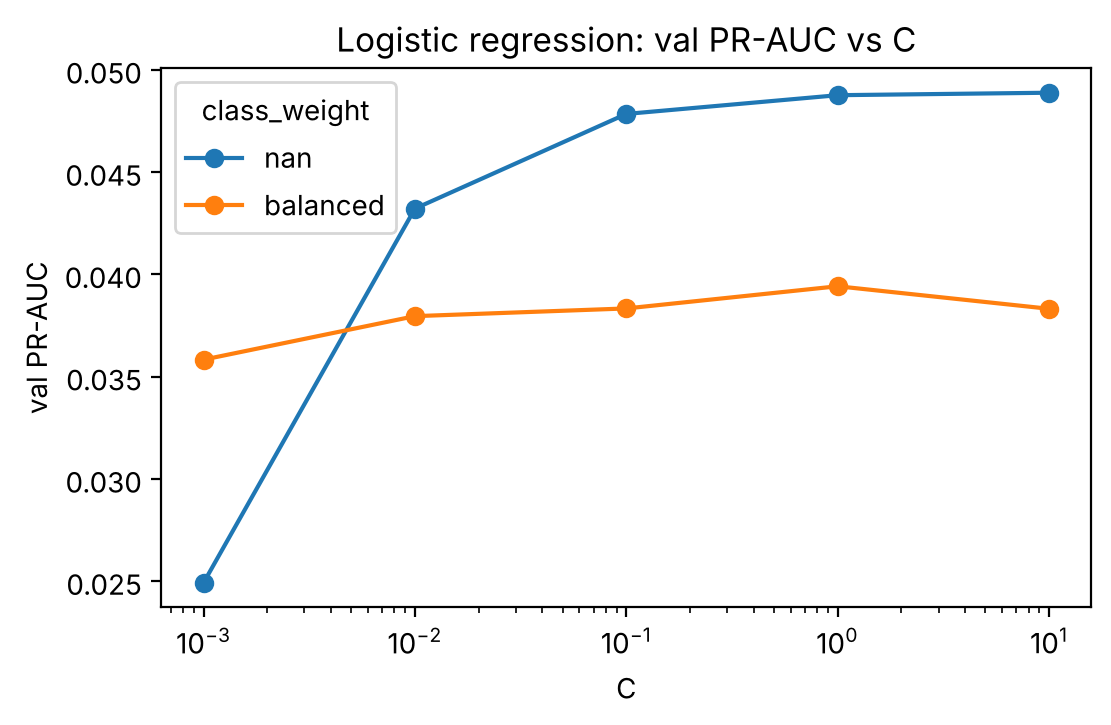

In [5]:
grid = pd.read_csv(PROJECT_ROOT / "artifacts" / "models" / "grid_logistic_regression.csv")
pivot = grid.pivot(index="C", columns="class_weight", values="val_pr_auc")
display(pivot.round(4))
ax = pivot.plot(marker="o", logx=True, figsize=(6, 3.5))
ax.set_ylabel("val PR-AUC"); ax.set_title("Logistic regression: val PR-AUC vs C"); plt.show()

## 5. What did the best logistic regression learn?
Inputs are standardised, so each coefficient is the change in **log-odds of laundering** for a one-standard-deviation increase, or for a category being present. Positive means more likely laundering. `exp(coef)` is the odds multiplier.

In [6]:
import pickle
best = pickle.load(open(PROJECT_ROOT / "artifacts" / "models" / "logistic_regression.pkl", "rb"))
print("best params:", best["params"], "| val-F1 threshold:", round(best["threshold"], 4))
coef = T.logistic_coefficients(best["pipeline"])
pd.DataFrame({"coef": coef, "odds_multiplier": np.exp(coef)}).round(3)

best params: {'class_weight': None, 'C': 10.0} | val-F1 threshold: 0.0203


,coef,odds_multiplier
cat__payment_format_Cheque,-2.491,0.083
cat__payment_format_ACH,2.438,11.454
cat__payment_format_Credit Card,-2.280,0.102
bool__same_bank,-1.789,0.167
cat__payment_format_Cash,-1.703,0.182
cat__payment_format_Reinvestment,-1.378,0.252
counts__receiver_unique_senders_24h,0.905,2.473
cat__payment_format_Wire,-0.850,0.427
counts__receiver_txn_count_1h,-0.779,0.459
counts__receiver_txn_count_24h,-0.740,0.477


## 6. Threshold matters with class weights
A balanced model's probabilities are inflated, so the default 0.5 cut-off flags far too many transactions. The threshold is chosen on val to maximise F1.

In [7]:
s = T.positive_scores(best["pipeline"], X_val)
pd.DataFrame({"threshold 0.5": evaluate_scores(y_val, s, 0.5),
              "val-F1 threshold": evaluate_scores(y_val, s, best["threshold"])}).T[
    ["threshold", "precision", "recall", "f1", "tp", "fp", "fn"]].round(4)

,threshold,precision,recall,f1,tp,fp,fn
threshold 0.5,0.5000,0.0000,0.0000,0.0000,0.0,0.0,1082.0
val-F1 threshold,0.0203,0.0969,0.1128,0.1042,122.0,1137.0,960.0
